# Assignment 3 — Code Submission

**Submit:** this `.ipynb` file inside the required ZIP package, together with the required wav_examples/ folder.

**Group members (Name | ID):**  
- `Adi Issa | a1987954`  
- `Gaoyuan Chen | a1993974`  
- `Zaid Ul Quadir Qazi  | a1990366`  

**Date:** `1 Nov 2026`



**1. Set up Google Drive, project folders, and dependencies.**


In [ ]:
from pathlib import Path
import os
from google.colab import drive
drive.mount("/content/drive")


PROJECT_ROOT = Path("/content/drive/MyDrive/Semester_2_2026/Generative AI/A3LoRa")       # file location

RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_DIR = PROJECT_ROOT / "wav_examples"                         # Folder to save waves
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


requirements_path = PROJECT_ROOT / "requirements.txt"
print("File found:", requirements_path.is_file())  # should be True

%pip install -r "{requirements_path}"



Mounted at /content/drive
File found: True
  Cloning https://github.com/speechbrain/speechbrain.git to /tmp/pip-req-build-610v7w58
  Running command git clone --filter=blob:none --quiet https://github.com/speechbrain/speechbrain.git /tmp/pip-req-build-610v7w58
  Resolved https://github.com/speechbrain/speechbrain.git to commit c0241278f93ef02cd5191f03caf4e5f8e1292bf6
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.2/803.2 kB 34.6 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━

**Load Data**

In [ ]:
!rm -rf "/content/LJSpeech-1.1" "/content/LJSpeech-1.1.tar.bz2"

file_path = PROJECT_ROOT / "data" / "LJSpeech-1.1.tar.bz2"

!cp "{file_path}" "/content/LJSpeech-1.1.tar.bz2"

!tar -xjf "/content/LJSpeech-1.1.tar.bz2" -C "/content/"

In [ ]:
DATA_ROOT = Path("/content/LJSpeech-1.1")
print(os.listdir(DATA_ROOT))           # ['wavs', 'metadata.csv', 'README']
WAV_DIR = DATA_ROOT / "wavs"

print("Metadata:", (DATA_ROOT / "metadata.csv").exists())
print("WAV files:", len(list(WAV_DIR.glob("*.wav"))))

['metadata.csv', 'wavs', 'README']
Metadata: True
WAV files: 13100


**2. Import the required libraries.**


In [ ]:
import random
import time

import librosa
import librosa.display
import numpy as np
import pandas as pd
import soundfile as sf
import torch
import torchaudio

from google.colab import drive
from IPython.display import Audio, display
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader

from speechbrain.inference.classifiers import EncoderClassifier
from transformers import (
    SpeechT5Processor,
    SpeechT5ForTextToSpeech,
    SpeechT5HifiGan
)
from transformers.utils import logging
from huggingface_hub.utils import disable_progress_bars

import matplotlib.pyplot as plt
from unidecode import unidecode
from nemo_text_processing.text_normalization.normalize import Normalizer
import csv
import time
import string
import jiwer
import whisper

from collections import Counter
from peft import LoraConfig

**3. Set experiment parameters and random seeds.**


In [ ]:
SEED = 42
MAX_SAMPLES_A = 1000
MAX_SAMPLES_B = 2000
BATCH_SIZE = 8
LEARNING_RATE_A = 1e-5
LEARNING_RATE_B = 1e-4
EPOCHS = 20
SAMPLE_RATE = 16000

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Device:", DEVICE)

Device: cuda


# 1.1 Dataset handling & pre-processing (Rubric 1.1)

## 1.1.1 Dataset location and structure
- **Dataset:** LJSpeech  
- **Local path used:** `/content/drive/MyDrive/Semester_2_2026/GenerativeAI/A3LoRa/data/LJSpeech-1.1.tar.bz2`
- **Files/folders used:**  
  - `metadata.csv`  
  - `wavs/`

## 1.1.2 Audio preprocessing (document your choices)
State what you did and why:
- **Sampling rate:** `Resampled from 22,050 Hz to 16,000 Hz`  
- **Silence trimming / padding:** `Audio targets are padded per batch; padded frames are ignored during loss calculation.`  
- **Any filtering / normalization:** `none`

## 1.1.3 Text preprocessing (minimum: justify your choice)
- **Normalization:** `We used the normalised_text; then converted accented characters to ASCII, expanded listed abbreviations, lowercased, removed quotes/brackets, replaced hyphens/colons/semicolons with spaces, and collapsed extra spaces.Also, we add number normalised line to handle any number in future promte`  
- **Tokenizer / phonemizer (if used):** `SpeechT5Processor tokenizer; no separate phonemizer.`

## 1.1.4 Train/validation/test split (reproducible)
- **Split ratio:**  `80/10/10`  
- **Seed:** `42`  
- **How split is created:** `Random sampling and shuffling with seed 42`  
- **Any subset used:** `2,000 samples (1600/200/200); nested 1,000-sample subset (800/100/100).`

**4. Load the LJSpeech metadata.**


In [ ]:
data = pd.read_csv( DATA_ROOT / "metadata.csv", sep="|" , names=["utt_id", "raw_text", "normalised_text"], quoting=csv.QUOTE_NONE)          #  encoding="utf-8" , header=None

print(data.head(10).to_string(index=False))

assert len(data) == 13100
assert data["normalised_text"].notna().all()


    utt_id                                                                                                                                                    raw_text                                                                                                                                             normalised_text
LJ001-0001     Printing, in the only sense with which we are at present concerned, differs from most if not from all the arts and crafts represented in the Exhibition     Printing, in the only sense with which we are at present concerned, differs from most if not from all the arts and crafts represented in the Exhibition
LJ001-0002                                                                                                                              in being comparatively modern.                                                                                                                              in being comparatively modern.
LJ001-0003 For although the Chi

**5. Show character counts before cleaning.**


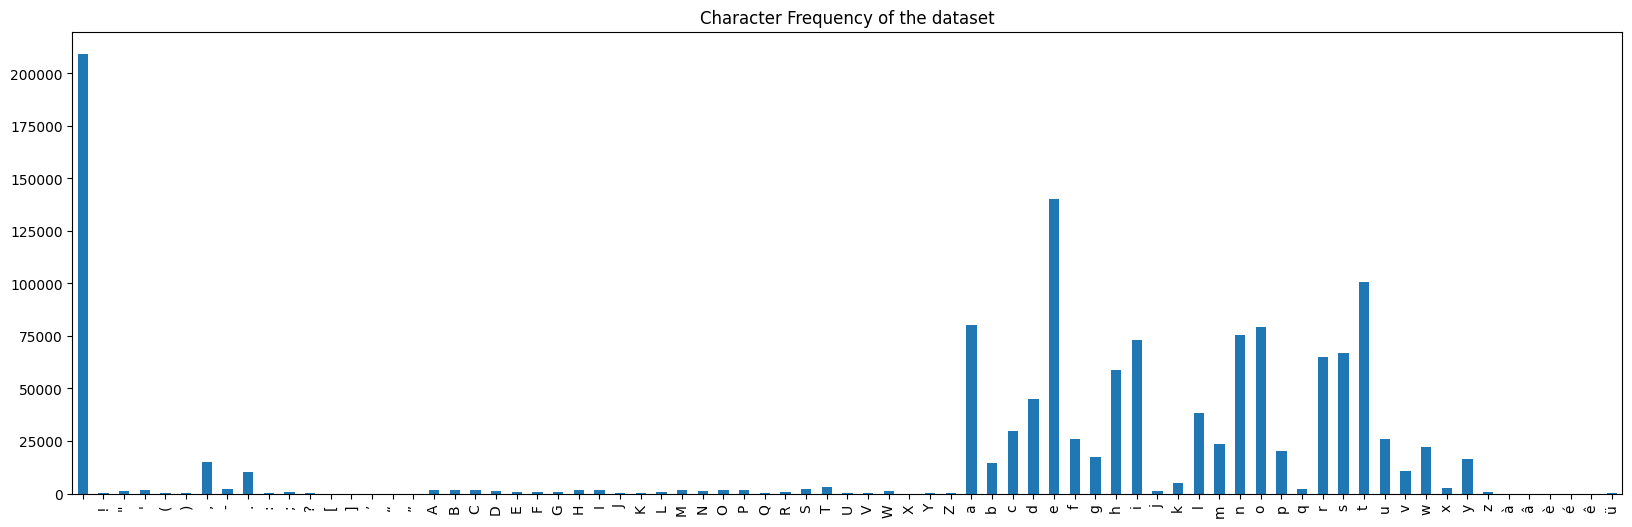

In [ ]:
counts = pd.Series(list("".join(data["normalised_text"].dropna()))).value_counts()

symbols = sorted(c for c in counts.index if not c.isalnum())
letters = sorted((c for c in counts.index if c.isalpha()))
other = sorted(c for c in counts.index if c not in symbols + letters)

counts = counts.reindex(symbols + letters + other)
counts.plot.bar(figsize=(20, 6), title="Character Frequency of the dataset")
plt.show()

**6. Clean the text and check WAV files.**


In [ ]:

normalizer = Normalizer(lang="en", input_case="cased")

def clean_text(text, num_handle=1):
    text = unidecode(text)                       # 1. non-ASCII -> ASCII
    if num_handle == 1:
        text = normalizer.normalize(text)        # 2. numbers -> words (new text only)
    for short, full in {"No.": "Number", "i.e." : "i e", "e.g.": "e g" }.items() :       # 3. expand abbreviations
        text = text.replace(short, full)
    text = text.lower()                          # 4. lowercase
    for symbol in '"()[]':                       # 5. remove quotes and brackets (not spoken)
        text = text.replace(symbol, "")
    text = text.replace(";", ",")                # 6. semicolon -> comma (keeps the pause)
    for symbol in "-:":                          # 7. hyphens and colons -> space
        text = text.replace(symbol, " ")
    text = " ".join(text.split())                # 8. single spaces
    if text.endswith(","):                       # 9. final comma -> full stop
        text = text[:-1]
        if not text.endswith("."):               #  "p.m.," becomes "p.m.", not "p.m.."
            text += "."
    return text


data["text"] = data["normalised_text"].map(clean_text)
data["wav_path"] = str(WAV_DIR) + "/" + data["utt_id"] + ".wav"
# Keep only rows with an existing WAV file.
files_exist = [Path(path).is_file() for path in data["wav_path"]]
data = data[files_exist]
data.head(5)

 NeMo-text-processing :: INFO     :: Creating ClassifyFst grammars.
INFO:NeMo-text-processing:Creating ClassifyFst grammars.


,utt_id,raw_text,normalised_text,text,wav_path
0,LJ001-0001,"Printing, in the only sense with which we are ...","Printing, in the only sense with which we are ...","printing, in the only sense with which we are ...",/content/LJSpeech-1.1/wavs/LJ001-0001.wav
1,LJ001-0002,in being comparatively modern.,in being comparatively modern.,in being comparatively modern.,/content/LJSpeech-1.1/wavs/LJ001-0002.wav
2,LJ001-0003,For although the Chinese took impressions from...,For although the Chinese took impressions from...,for although the chinese took impressions from...,/content/LJSpeech-1.1/wavs/LJ001-0003.wav
3,LJ001-0004,"produced the block books, which were the immed...","produced the block books, which were the immed...","produced the block books, which were the immed...",/content/LJSpeech-1.1/wavs/LJ001-0004.wav
4,LJ001-0005,the invention of movable metal letters in the ...,the invention of movable metal letters in the ...,the invention of movable metal letters in the ...,/content/LJSpeech-1.1/wavs/LJ001-0005.wav


**7. Show character counts after cleaning.**


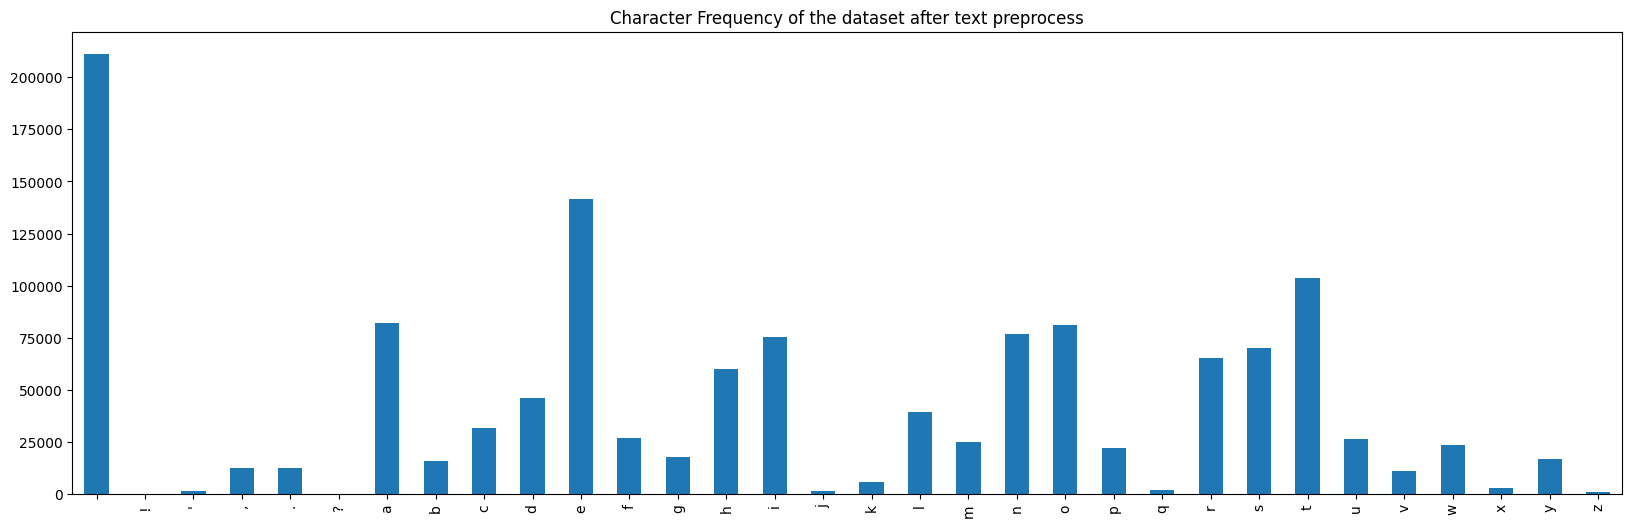

In [ ]:
counts = pd.Series(list("".join(data["text"].dropna()))).value_counts()
symbols = sorted(c for c in counts.index if not c.isalnum())
letters = sorted((c for c in counts.index if c.isalpha()))
other = sorted(c for c in counts.index if c not in symbols + letters)

counts = counts.reindex(symbols + letters + other)
counts.plot.bar(figsize=(20, 6), title="Character Frequency of the dataset after text preprocess")
plt.show()

**8. Plot sample mel spectrograms.**


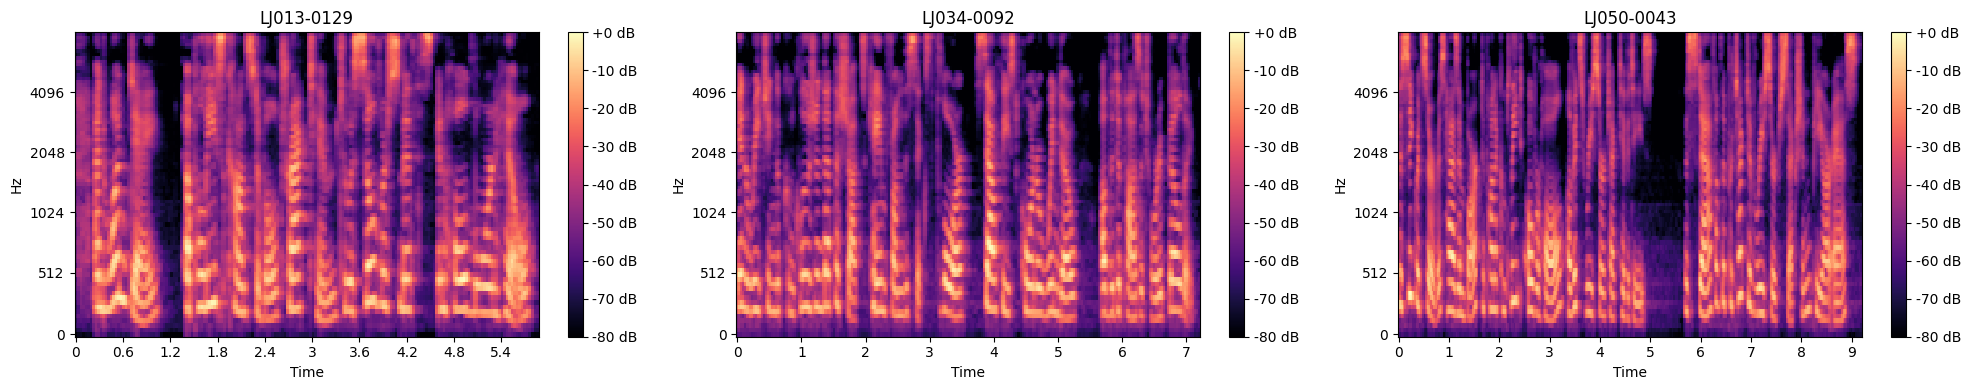

In [ ]:
samples = data.sample(n=3)

plt.figure(figsize=(20, 4))
for i in range(3):
    row = samples.iloc[i]
    audio, _ = librosa.load(row["wav_path"], sr=SAMPLE_RATE, mono=True)  # representing the sound’s changing amplitude,
    mel = librosa.feature.melspectrogram(y=audio, sr=SAMPLE_RATE,  n_mels=80)
    mel_db = librosa.power_to_db(mel, ref=mel.max())  # calcuate 10 * log10(S / ref)

    plt.subplot(1, 3, i + 1)
    image = librosa.display.specshow(mel_db, sr=SAMPLE_RATE, x_axis="time", y_axis="mel")
    plt.colorbar(image, format="%+d dB")
    plt.title(row["utt_id"])

plt.tight_layout()
plt.show()


**Audio Processing**


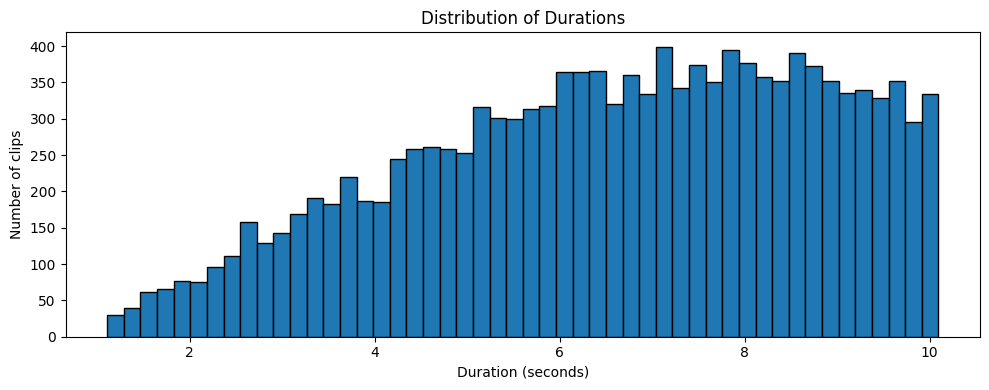

count    13100.000000
mean         6.573823
std          2.185431
min          1.110068
25%          4.987800
50%          6.764127
75%          8.389524
max         10.096190
Name: duration, dtype: float64


In [ ]:
data["duration"] = data["wav_path"].apply(lambda path: sf.info(str(path)).duration)

data["duration"].hist(bins=50, edgecolor="black", figsize=(10, 4))

plt.title("Distribution of Durations")
plt.xlabel("Duration (seconds)")
plt.ylabel("Number of clips")
plt.grid(False)
plt.tight_layout()
plt.show()

print(data["duration"].describe())

In [ ]:
print("clips < 1 s  :", (data["duration"] < 1.0).sum())
print("clips < 1.5 s:", (data["duration"] < 1.5).sum())
print("clips < 1.8 s:", (data["duration"] < 1.8).sum())
print("clips < 2 s:", (data["duration"] < 2).sum())

clips < 1 s  : 0
clips < 1.5 s: 82
clips < 1.8 s: 184
clips < 2 s: 272


Keep The Data above 2 sec

In [ ]:
data = data[data["duration"] >= 2].reset_index(drop=True)

**9. Create the 2,000- and 1,000-sample data splits.**


In [ ]:
# Get Samples 2k
data_s = data.sample(n= MAX_SAMPLES_B, random_state=SEED).reset_index(drop=True)


train_data, remaining_data = train_test_split(data_s,test_size=0.20,random_state=SEED,shuffle=True)
val_data, test_data = train_test_split( remaining_data, test_size=0.50,random_state=SEED, shuffle=True)

train_data = train_data.reset_index(drop=True)
val_data = val_data.reset_index(drop=True)
test_data = test_data.reset_index(drop=True)


train_data_1k = train_data.sample(n= int(MAX_SAMPLES_A *0.8) , random_state=SEED).reset_index(drop=True)
val_data_1k  = val_data.sample(n= int(MAX_SAMPLES_A * 0.1) , random_state=SEED).reset_index(drop=True)
test_data_1k = test_data.sample(n= int(MAX_SAMPLES_A * 0.1) , random_state=SEED).reset_index(drop=True)

print ("Experiment with 1000 samples")
print("Train:", len(train_data_1k))         # 80%
print("Validation:", len(val_data_1k))      # 10%
print("Test:", len(test_data_1k))           # 10%
print ("---------------------------------")



print ("\nExperiment with 2000 samples")
print("Train:", len(train_data))         # 80%
print("Validation:", len(val_data))      # 10%
print("Test:", len(test_data))           # 10%

Experiment with 1000 samples
Train: 800
Validation: 100
Test: 100
---------------------------------

Experiment with 2000 samples
Train: 1600
Validation: 200
Test: 200


# 1.2 End-to-end TTS pipeline implementation (Rubric 1.2)

## 1.2.1 Pipeline overview (high level)
Describe the approach briefly:
- **TTS approach:** `Fine-tune pretrained SpeechT5 on LJSpeech.`   and LoRa for Experiment E & F
- **Key components:**  
  - Text front-end: `clean_text() followed by the SpeechT5Processor tokenizer`  
  - Acoustic model: `microsoft/speecht5_tts, fine-tuned separately for expA–expD`  
  - Vocoder / waveform generator: `microsoft/speecht5_hifigan converts the model output to audio.`  
- **Output:** Playable 16,000 Hz .wav files

## 1.2.2 Environment & dependencies (reproducible)
Provide at least one dependency definition file and document:
- **OS:** `Google Colab`  
- **Python:** `3.13`  
- **CUDA (if used):** `13.0`  
- **GPU (if used):** `NVIDIA A100; 40GB RAM`


## 1.2.3 Training command(s)
Provide the exact command(s) you used, for example:
Run these notebook cells to train the four experiments:

```python
run_experiment(experiments[0])  # exp0: No Training
run_experiment(experiments[1])  # expA: 1,000 samples, learning rate 1e-5
run_experiment(experiments[2])  # expB: 1,000 samples, learning rate 1e-4
run_experiment(experiments[3])  # expC: 2,000 samples, learning rate 1e-5
run_experiment(experiments[4])  # expD: 2,000 samples, learning rate 1e-4
run_experiment(experiments[5])  # expE: 1,000 samples, learning rate 1e-5  LoRa
run_experiment(experiments[6])  # expF: 1,000 samples, learning rate 1e-4  LoRa
```


## 1.2.4 Inference: a single “text → wav” entrypoint (must be easy to run)

After running the notebook setup cells, generate audio from any text:

```python
model = SpeechT5ForTextToSpeech.from_pretrained(
    str(CHECKPOINT_DIR / "expA")
).to(DEVICE)

generate_examples(["Hello world."], model, run_name="hello")
```

- **Generated WAV:** `PROJECT_ROOT/wav_examples/hello_01.wav`
- **Checkpoints:** `PROJECT_ROOT/checkpoints/expA` (and similarly for expB–expD)
- **Checkpoint access:** Include the checkpoints in the submission or provide a download link.

# 1.3 Experimental methodology

## 1.3.1 Controlled experiments

All runs start from the same pretrained SpeechT5 model, use the SpeechT5 HiFi-GAN vocoder, batch size 8, and seed 42.

### Experiment A (baseline)

- **Name:** `expA`
- **Purpose:** Baseline fine-tuning with 1,000 samples.
- **Key settings:** 800 train / 100 validation / 100 test; learning rate `1e-5`; epochs set by `EPOCHS`.

### Experiment B (learning-rate change)

- **Name:** `expB`
- **Controlled change vs expA:** Learning rate increases from `1e-5` to `1e-4`.
- **Key settings:** Uses the **same 1,000-sample split**, model, batch size, and number of epochs as expA.

### Experiment C (larger dataset)

- **Name:** `expC`
- **Change vs expA:** Uses 2,000 samples instead of 1,000, with the same learning rate (`1e-5`).
- **Key settings:** 16,00 train / 200 validation / 200 test.

### Experiment D (learning-rate change)

- **Name:** `expD`
- **Controlled change vs expC:** Learning rate increases from `1e-5` to `1e-4`.
- **Key settings:** Uses the **same 2,000-sample split**, model, batch size, and number of epochs as expC.

## Additional Experiment using LoRA

### Experiment E  LoRa with 1e-5

- **Name:** `expE` Using LoRa
- **Controlled change vs expA:** Using LoRa instead of full tune the model`.
- **Key settings:** Uses the **same 1,000-sample split**, model, batch size, and number of epochs as expC.

### Experiment F LoRa with 1e-4

- **Name:** `expF`   Using LoRa
- **Controlled change vs expB:** Using LoRa instead of full tune the model.
- **Key settings:** Uses the **same 1,000-sample split**, model, batch size, and number of epochs as expC.





## 1.3.2 What was saved for reproducibility

- **Config files:** Settings are currently recorded in the notebook; no separate YAML files are required unless added.
- **Random seeds:** `SEED = 42`, set in the setup code and reset before each run.
- **Checkpoints:** `PROJECT_ROOT/checkpoints/expA` through `expD`.
- **Logs/results:** Training and validation loss plots appear in the notebook; per-sample evaluation results are saved in `RESULTS_DIR` as experiment metrics CSV files

**10. Load SpeechT5, the vocoder, and the speaker embedding.**


In [ ]:
disable_progress_bars()
logging.set_verbosity_error()
processor = SpeechT5Processor.from_pretrained("microsoft/speecht5_tts")
model = SpeechT5ForTextToSpeech.from_pretrained("microsoft/speecht5_tts").to(DEVICE)
vocoder = SpeechT5HifiGan.from_pretrained("microsoft/speecht5_hifigan").to(DEVICE)

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/158 [00:00<?, ?it/s]

**Get the speaker embedding**

In [ ]:
device_str = str(DEVICE)
speaker_encoder = EncoderClassifier.from_hparams(source="speechbrain/spkrec-xvect-voxceleb",run_opts={"device": device_str})
speaker_encoder.eval()

def extract_embedding(wav_path):
    waveform, source_rate = torchaudio.load(wav_path)
    waveform = waveform.mean(dim=0, keepdim=True)# Convert to mono
    # Resample for the X-vector model
    if source_rate != SAMPLE_RATE:  # resample the wave to 16,000
        waveform = torchaudio.functional.resample(waveform,source_rate,SAMPLE_RATE)
    with torch.no_grad():
        embedding = speaker_encoder.encode_batch(waveform.to(device_str)).squeeze()
    return torch.nn.functional.normalize(embedding,dim=0).cpu()


# Select reproducibly from the the training  split ( select 30 samples)
reference_rows = train_data.sample(n=30, random_state=SEED)
reference_embeddings = [extract_embedding(path)for path in reference_rows["wav_path"]]   # get the embedded

speaker_embedding = torch.stack(reference_embeddings).mean(dim=0)   # Get the mean if the 30
print("Speaker embedding shape:", speaker_embedding.shape)

INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Fetching from HuggingFace Hub 'speechbrain/spkrec-xvect-voxceleb' if not cached
INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Fetching from HuggingFace Hub 'speechbrain/spkrec-xvect-voxceleb' if not cached
INFO:speechbrain.utils.fetching:Fetch mean_var_norm_emb.ckpt: Fetching from HuggingFace Hub 'speechbrain/spkrec-xvect-voxceleb' if not cached
INFO:speechbrain.utils.fetching:Fetch classifier.ckpt: Fetching from HuggingFace Hub 'speechbrain/spkrec-xvect-voxceleb' if not cached
INFO:speechbrain.utils.fetching:Fetch label_encoder.txt: Fetching from HuggingFace Hub 'speechbrain/spkrec-xvect-voxceleb' if not cached
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, mean_var_norm_emb, classifier, label_encoder


Speaker embedding shape: torch.Size([512])


**11. Define the dataset and batch collator.**


In [ ]:
class LJSpeechDataset(Dataset):

    def __init__(self, table):
        self.table = table.reset_index(drop=True)

    def __len__(self):
        return len(self.table)

    def __getitem__(self, index):
        row = self.table.iloc[index]
        audio, _ = librosa.load( row["wav_path"], sr=SAMPLE_RATE, mono=True)           # return Audio numpy "time_sec*sample_rate", and sample rate
        audio, _ = librosa.effects.trim(audio, top_db=45)       # remove silence at start and end
        features = processor(text=row["text"],audio_target=audio, sampling_rate=SAMPLE_RATE, return_attention_mask=False) # return

        return {
            "input_ids": features["input_ids"],
            "labels": features["labels"][0],
            "speaker_embeddings": speaker_embedding,
            "text": row["text"],
            "wav_path": row["wav_path"]}

class DataCollator:

    def __init__(self, processor, reduction_factor):
        self.processor = processor
        self.reduction_factor = reduction_factor
    def __call__(self, features):
        input_features = []
        label_features = []
        speaker_features = []
        texts = []
        wav_paths = []

        for item in features:
            input_features.append({"input_ids": item["input_ids"]})
            label_features.append({"input_values": item["labels"]})
            speaker_features.append(item["speaker_embeddings"])
            texts.append(item["text"])
            wav_paths.append(item["wav_path"])

        # Collates the audio and text inputs, as well as their targets, into a padded batch.
        #  Pad text and audio to the longest example in this batch.
        # The default SpeechT5 reduction factor is 2: the decoder predicts two mel frames per step
        batch = self.processor.pad( input_ids=input_features, labels=label_features, pad_to_multiple_of=self.reduction_factor,  return_tensors="pt")

        # Mark padded audio frames with -100 so they do not affect loss.
        batch["labels"] = batch["labels"].masked_fill( batch["decoder_attention_mask"].unsqueeze(-1).ne(1),-100 )
        del batch["decoder_attention_mask"]

        batch["speaker_embeddings"] = torch.stack(speaker_features)
        # Keep original information for WER evaluation.
        batch["text"] = texts
        batch["wav_path"] = wav_paths

        return batch

**12. Create the 1,000-sample DataLoaders.**

In [ ]:
train_dataset_1k = LJSpeechDataset(train_data_1k)
val_dataset_1k = LJSpeechDataset(val_data_1k)
test_dataset_1k = LJSpeechDataset(test_data_1k)
#######



data_collator = DataCollator(processor,model.config.reduction_factor)

generator = torch.Generator().manual_seed(SEED)

train_loader_1k = DataLoader(
    train_dataset_1k,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=generator,
    collate_fn=data_collator,
    num_workers=4,
    pin_memory=torch.cuda.is_available()
)

val_loader_1k = DataLoader(
    val_dataset_1k,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=data_collator,
    num_workers=4,
    pin_memory=torch.cuda.is_available()
)

test_loader_1k = DataLoader(
    test_dataset_1k,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=data_collator,
    num_workers=4,
    pin_memory=torch.cuda.is_available()
)

loaders_1k = { "train": train_loader_1k, "val": val_loader_1k,"test": test_loader_1k }

print("Train batches:", len(loaders_1k["train"]))
print("Validation batches:", len(loaders_1k["val"]))
print("Test batches:", len(loaders_1k["test"]))


Train batches: 100
Validation batches: 13
Test batches: 13


**13. Inspect a sample batch.**

In [ ]:
batch = next(iter(loaders_1k["train"]))
print("Text tokens:", batch["input_ids"].shape)
print("Mel labels:", batch["labels"].shape)
print("Speaker vectors:", batch["speaker_embeddings"].shape)

Text tokens: torch.Size([8, 136])
Mel labels: torch.Size([8, 562, 80])
Speaker vectors: torch.Size([8, 512])


**14. Create the 2,000-sample DataLoaders.**

In [ ]:
train_dataset = LJSpeechDataset(train_data)
val_dataset = LJSpeechDataset(val_data)
test_dataset = LJSpeechDataset(test_data)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=generator,
    collate_fn=data_collator,
    num_workers=8,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=data_collator,
    num_workers=8,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=data_collator,
    num_workers=8,
    pin_memory=torch.cuda.is_available()
)

loader_f = { "train": train_loader, "val": val_loader,"test": test_loader }

print("Train batches:", len(loader_f["train"]))
print("Validation batches:", len(loader_f["val"]))
print("Test batches:", len(loader_f["test"]))

Train batches: 200
Validation batches: 25
Test batches: 25


**15. Define validation-loss calculation.**


In [ ]:
def evaluation(model, val_loader):
    epoch_val_loss = []
    model.eval()
    with torch.no_grad():
        for batch in val_loader:
            model_batch  = { key: value.to(DEVICE) for key, value in batch.items() if torch.is_tensor(value)  }
            output = model(**model_batch )
            epoch_val_loss.append( output.loss.item())

    return sum(epoch_val_loss) / len(epoch_val_loss)

In [ ]:
BASE_MODEL_ID = "microsoft/speecht5_tts"
LORA_ADAPTER_NAME = "ljspeech"


def build_speecht5(training_mode):
    model = SpeechT5ForTextToSpeech.from_pretrained(BASE_MODEL_ID)
    model.config.use_guided_attention_loss = True

    if training_mode == "frozen":
        model.requires_grad_(False)

    elif training_mode == "full":
        model.requires_grad_(True)

    elif training_mode == "lora":
        model.requires_grad_(False)

        lora_config = LoraConfig(
            r=8,
            lora_alpha=8,
            lora_dropout=0.05,
            target_modules= ["q_proj", "k_proj", "v_proj", "out_proj", "intermediate_dense", "output_dense","feat_out"],
            bias="none",
            inference_mode=False,
        )

        model.add_adapter(lora_config, adapter_name=LORA_ADAPTER_NAME)
        model.set_adapter(LORA_ADAPTER_NAME)

    else:
        raise ValueError(f"Unknown training mode: {training_mode}")

    model.config.use_cache = False
    model = model.to(DEVICE)

    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())

    print(f"Mode: {training_mode}")
    print(f"Trainable parameters: {trainable:,}/{total:,} ({100 * trainable / total:.3f}%)")

    return model

**16. Define the training loop and checkpoint saving.**


In [ ]:
def train(model, data_loader, lr=LEARNING_RATE_A, epoch_num=EPOCHS, check_point= None):

    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],lr=lr, weight_decay=0.01)
    train_loss = []
    val_loss = []
    best_val_loss = float("inf")

    print(f"{'Epoch':<10}{'Batch':<12}{'Train Loss':>18}{'Validation Loss':>18}")
    print("-" * 58)

    for epoch in range(epoch_num):

        model.train()
        epoch_train_loss = []
        for bn, batch in enumerate(data_loader["train"], start=1):
            model_batch = {key: value.to(DEVICE) for key, value in batch.items() if torch.is_tensor(value) }
            # moves every tensor in the batch to the same device

            optimizer.zero_grad()
            output = model(**model_batch)   # same as input_ids=batch["input_ids"], attention_mask = batch['attention_mask'] , labels=batch["labels"], speaker_embeddings=batch["speaker_embeddings"])
            loss = output.loss
            if not torch.isfinite(loss):
                raise FloatingPointError(f"Non-finite loss at epoch {epoch + 1}, batch {bn}")
            loss.backward()
            optimizer.step()
            epoch_train_loss.append(loss.item())
            average_train_loss = sum(epoch_train_loss) / len(epoch_train_loss)
            print(f"\r{f'{epoch + 1}/{epoch_num}':<10}{f'{bn}/{len(data_loader['train'])}':<12}{average_train_loss:>18.4f}{'-':>18}", end="")


        average_train_loss = (sum(epoch_train_loss)/ len(epoch_train_loss))

        average_val_loss = evaluation( model, data_loader["val"] )

        train_loss.append(average_train_loss)
        val_loss.append(average_val_loss)

        print(f"\r{f'{epoch + 1}/{epoch_num}':<10}{f'{bn}/{len(data_loader['train'])}':<12}{average_train_loss:>18.4f}{average_val_loss:>18.4f}", end="")
        print()

        if average_val_loss < best_val_loss:
            best_val_loss = average_val_loss
            model.save_pretrained(check_point)
            processor.save_pretrained(check_point)
            if (check_point / "adapter_config.json").is_file():
                print(f"Saved best LoRA adapter: {check_point}")


    print("Training completed")
    print(f"Best validation loss: {best_val_loss:.4f}")

    return {"Training Loss": train_loss, "Validation Loss": val_loss}

**17. Function for latency, RTF, and WER evaluation.**

In [ ]:
asr_model = whisper.load_model("base.en", device=DEVICE)

def evaluation_metrics(model, test_loader, run_name):

    model.eval()
    vocoder.eval()
    rows = []
    sample_number = 0
    normalise = jiwer.Compose([jiwer.RemovePunctuation(), jiwer.RemoveMultipleSpaces(), jiwer.Strip()])

    for batch in test_loader:
        for i in range(len(batch["text"])):
            sample_number += 1
            print(f"\r Sample {sample_number}/{len(test_loader.dataset)}     ", end="")
            ref_text = batch["text"][i]
            ref_path = batch["wav_path"][i]

            # Already processed by the dataset and collator.
            input_ids = batch["input_ids"][i]
            input_ids = input_ids[input_ids != processor.tokenizer.pad_token_id]   # remove the pading
            input_ids = input_ids.unsqueeze(0).to(DEVICE)         # add batch

            speaker = batch["speaker_embeddings"][i].unsqueeze(0).to(DEVICE)

            # Warm-up: run once without timing, so the first prompt is not slower than the rest.
            if sample_number == 1:
                with torch.no_grad():
                    model.generate_speech(input_ids, speaker_embeddings=speaker, vocoder=vocoder, maxlenratio=8.0)
                if DEVICE == "cuda":
                    torch.cuda.synchronize()

            # Measure generation time.
            latencies, wer_percent, audio_seconds, rtf, predicted_text = [], [], [], [], []
            best_sample = 0
            best_wer = 100
            for run in range(5):        #  5 time run
                torch.manual_seed(SEED + run)

                if DEVICE == "cuda":
                    torch.cuda.synchronize()
                start = time.time()
                with torch.no_grad():
                    speech = model.generate_speech(input_ids, speaker_embeddings=speaker, vocoder=vocoder, maxlenratio=8.0)
                if DEVICE == "cuda":
                    torch.cuda.synchronize()
                latency_sample = time.time() - start
                latencies.append(latency_sample)

                generated_audio = speech.cpu().numpy().reshape(-1)
                audio_seconds_sample  = len(generated_audio) / SAMPLE_RATE
                audio_seconds.append (audio_seconds_sample)

                rtf_sample = latency_sample / audio_seconds_sample
                rtf.append(rtf_sample)

                asr_audio, _ = librosa.effects.trim(generated_audio, top_db=45)
                # WER
                predicted_text_sample = asr_model.transcribe(
                      asr_audio.astype(np.float32),  # your generated audio is 16 kHz
                      language="en",
                      fp16=(DEVICE == "cuda"),
                      verbose=None)["text"]
                predicted_text.append(predicted_text_sample)

                wer_sample = 100 * jiwer.wer(normalise(clean_text(ref_text, num_handle = 1)),normalise(clean_text(predicted_text_sample, num_handle = 1)))
                wer_sample = min(wer_sample, 100)
                wer_percent.append(wer_sample)

                if wer_sample <= best_wer:
                    best_sample = run
                    best_wer = wer_sample

            # mean of the 5 runs
            rows.append({
                "sample": sample_number,
                "reference_text": ref_text,
                "best_wer": wer_percent[best_sample],
                "predicted_text": predicted_text[best_sample],
                "latency_seconds": np.mean(latencies),
                "audio_seconds": np.mean(audio_seconds),
                "rtf": np.mean(rtf),
                "wer_percent": np.mean(wer_percent),
            })

    print()
    df = pd.DataFrame(rows)
    means = df[["best_wer","latency_seconds", "audio_seconds", "rtf", "wer_percent"]].mean()
    df.loc[len(df)] = {
    "sample": "MEAN",
    "best_wer": df["best_wer"].mean(),
    "latency_seconds": df["latency_seconds"].mean(),
    "audio_seconds": df["audio_seconds"].mean(),
    "rtf": df["rtf"].mean(),
    "wer_percent": df["wer_percent"].mean(),
    }

    output_path = RESULTS_DIR / f"{run_name}_metrics_Testset.csv"
    df.to_csv(output_path, index=False)
    print(f"\nSaved: {output_path}")


    return means["latency_seconds"], means["rtf"], means["wer_percent"]

100%|████████████████████████████████████████| 139M/139M [00:00<00:00, 319MiB/s]


**18. Function for WAV generation and its metrics.**


In [ ]:
def generate_examples(Prompts_list, model, run_name ="A"):

    PROMPTS_C = Prompts_list if run_name == "Exp0" else [clean_text(p, num_handle=1) for p in Prompts_list]   # same cleaning as the training text

    results = []
    model.eval()
    vocoder.eval()
    speaker = speaker_embedding.unsqueeze(0).to(DEVICE)

    normalise = jiwer.Compose([jiwer.RemovePunctuation(), jiwer.RemoveMultipleSpaces(), jiwer.Strip()])

    # Warm-up: run once without timing, so the first prompt is not slower than the rest.
    warm_ids = processor(text=PROMPTS_C[0], return_tensors="pt")["input_ids"].to(DEVICE)
    with torch.no_grad():
        model.generate_speech(warm_ids, speaker_embeddings=speaker, vocoder=vocoder, maxlenratio=8.0)
    if DEVICE == "cuda":
        torch.cuda.synchronize()


    for index, text in enumerate(PROMPTS_C, start=1):
        input_ids = processor(text=text, return_tensors="pt")["input_ids"].to(DEVICE)
        ref_text = normalise(clean_text(text, num_handle=1))
        latencies, audios, rtf, audio_seconds, wer_percent, predicted_text =[], [], [], [], [], []
        best_sample = 0
        best_wer = 100
        best_audio = 1e9
        for run in range(5):        #  5 time run
            torch.manual_seed(SEED + run)
            if DEVICE == "cuda":
                torch.cuda.synchronize()
            start = time.time()

            with torch.no_grad():
                speech = model.generate_speech(
                    input_ids,
                    speaker_embeddings=speaker,
                    vocoder=vocoder,
                    maxlenratio=8.0, )

            if DEVICE == "cuda":
                torch.cuda.synchronize()
            latency_sample = time.time() - start
            latencies.append(latency_sample)

            audio = speech.cpu().numpy().reshape(-1)
            audios.append(audio)
            audio_seconds_sample = len(audio) / SAMPLE_RATE
            audio_seconds.append(audio_seconds_sample)
            rtf.append(latency_sample / audio_seconds_sample)
            # Whisper expects a 16 kHz waveform; SAMPLE_RATE is 16000.
            asr_audio, _ = librosa.effects.trim(audio, top_db=45)
            asr_text = asr_model.transcribe(
                asr_audio.astype(np.float32),
                language="en",
                fp16=(DEVICE == "cuda"),
                verbose=None
            )["text"]
            predicted_text.append(asr_text)

            wer_sample = 100 * jiwer.wer(ref_text,normalise(clean_text(asr_text, num_handle = 1)))
            wer_sample = min(wer_sample, 100)
            wer_percent.append(wer_sample)
            # Best run: lowest WER first, then shortest time
            if wer_sample < best_wer or (wer_sample == best_wer and audio_seconds_sample < best_audio):
                best_sample = run
                best_wer = wer_sample
                best_audio = audio_seconds_sample

        output_path = OUTPUT_DIR / f"T5_{run_name}_{index:02d}.wav"
        sf.write(str(output_path), audios[best_sample], SAMPLE_RATE)

        results.append({
            "file": output_path.name,
            "prompt": Prompts_list[index - 1],
            "best_wer": wer_percent[best_sample],
            "asr_text": predicted_text[best_sample],
            "latency_seconds": np.mean(latencies),
            "audio_seconds": np.mean(audio_seconds),
            "rtf": np.mean(rtf),
            "wer_percent": np.mean(wer_percent),
            })



    metrics = pd.DataFrame(results)
    metrics.loc[len(metrics)] = {
        "file": "MEAN",
        "best_wer": metrics["best_wer"].mean(),
        "latency_seconds": metrics["latency_seconds"].mean(),        # Generation Time
        "audio_seconds": metrics["audio_seconds"].mean(),
        "rtf": metrics["rtf"].mean(),
        "wer_percent": metrics["wer_percent"].mean()
    }


    csv_path = RESULTS_DIR / f"{run_name}_metrics_generation.csv"
    metrics.to_csv(csv_path, index=False)
    print(f"\nSaved: {csv_path}")

    print (f"{run_name} Result")
    print(metrics[["file","best_wer", "latency_seconds", "audio_seconds", "rtf", "wer_percent"]].to_string(index=False))


    first_file = OUTPUT_DIR / f"T5_{run_name}_01.wav"
    display(Audio(filename=str(first_file)))


**19. Function for the complete experiment workflow.**

In [ ]:
def run_experiment(experiments_index):
  experiment_start = time.time()
  run_name, loaders, learning_rate, training_mode = experiments_index

  print(f"\n -----------Starting {run_name} -----------")
  run_checkpoint_dir = CHECKPOINT_DIR / run_name
  run_checkpoint_dir.mkdir(parents=True, exist_ok=True)

  random.seed(SEED)
  np.random.seed(SEED)
  torch.manual_seed(SEED)
  generator.manual_seed(SEED)  # reset the generator used by the training DataLoaders
  logging.set_verbosity_error()

  model = build_speecht5(training_mode)

  if training_mode != "frozen":     # exp 0 it will generate audio with training
      # 1. Train the model.
      history = train(model,loaders ,lr=learning_rate, epoch_num= EPOCHS, check_point=run_checkpoint_dir)

      # 2. Plot training and validation loss.
      train_losses = history["Training Loss"]
      val_losses = history["Validation Loss"]
      epochs = range(1, len(train_losses) + 1)

      best_val = min(val_losses)
      best_epoch = val_losses.index(best_val) + 1

      plt.figure(figsize=(8, 4))
      plt.plot(epochs, train_losses, "o-", label="Training loss")
      plt.plot(epochs, val_losses, "o-", label="Validation loss")
      plt.plot(best_epoch, best_val, "*", markersize=10, label=f"Best val loss ({best_val:.4f} @ epoch {best_epoch})")
      plt.xlabel("Epoch")
      plt.ylabel("Loss")
      plt.title(f"{run_name} - {training_mode}")
      plt.legend()
      plt.show()

      # Free the training model before loading its best checkpoint.
      del model
      torch.cuda.empty_cache()

      # load best model parameters from check point
      if training_mode == "lora":
          assert (run_checkpoint_dir / "adapter_config.json").exists(), "LoRA adapter was not saved"
          model = SpeechT5ForTextToSpeech.from_pretrained(BASE_MODEL_ID)
          model.load_adapter(str(run_checkpoint_dir),adapter_name=LORA_ADAPTER_NAME,)
          model.set_adapter(LORA_ADAPTER_NAME)
          print("Loaded adapter:", model.active_adapters())
      else:
          model = SpeechT5ForTextToSpeech.from_pretrained(str(run_checkpoint_dir))
          print("Best Model Loaded")

#############################################
  model.config.use_cache = False
  model = model.to(DEVICE)
  e_time = time.time() - experiment_start
  print ( f"Training Time = {e_time:.3f} sec")

  # 3. Test loss.

  test_loss = evaluation(model, loaders["test"])
  print(f"{run_name}, {training_mode}, Testing loss: {test_loss:.4f}")

  # 4. Generation metrics.
  print('\n ---- evaluation metrics ----')

  mean_lat, mean_rtf, mean_wer = evaluation_metrics(model, loaders["test"], run_name)
  print(f"Mean latency: {mean_lat:.4f}")
  print(f"Mean RTF: {mean_rtf:.4f}")
  print(f"Mean WER: {mean_wer:.2f}%")
  print("Each file in the testing was generated 5 times, and the mean result was calculated.")

  generate_examples(PROMPTS, model, run_name)  # Save this run's 12 WAV files.
  print("Each prompts was generated 5 times, and the mean result was calculated.")
  del model
  torch.cuda.empty_cache()
  print("-" * 70)


**20. List the 12 evaluation prompts.**


In [ ]:
PROMPTS = [
    "The quick brown fox jumps over the lazy dog.",
    "Adelaide has great weather in spring.",
    "Thank you for listening to this file.",
    "Our group did excellent work on assignment 3.",
    "Can you hear the difference between these 2 voices?",
    "What a great result for our first experiment!",
    "We need clean text, and enough training time.",
    "The first model was fast, the second model sounded more natural.",
    "I don't believe it is ready, but we will try it again tomorrow.",
    "At the university, Dr. Brown and Mrs. Lee met Mr. Clark.",
    "The class begins at nine and there are forty-five students in the class.",
    "The model should be able to read new sentences clearly, and maintain a consistent reading speed; and pause at the correct location."
]


**21. Configure the four experiments.**


In [ ]:
experiments = [
    ("Exp0", loaders_1k, 0.0, "frozen"),  # Single control

    ("ExpA", loaders_1k, LEARNING_RATE_A, "full"),
    ("ExpB", loaders_1k, LEARNING_RATE_B, "full"),
    ("ExpC", loader_f, LEARNING_RATE_A, "full"),
    ("ExpD", loader_f, LEARNING_RATE_B, "full"),

    ("ExpE", loaders_1k, LEARNING_RATE_A, "lora"),
    ("ExpF", loaders_1k, LEARNING_RATE_B, "lora"),
]

**Run experiment 0: No Training.**


In [ ]:
run_experiment(experiments[0])


 -----------Starting Exp0 -----------


Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Mode: frozen
Trainable parameters: 0/144,431,684 (0.000%)
Training Time = 0.885 sec
Exp0, frozen, Testing loss: 0.6802

 ---- evaluation metrics ----
 Sample 100/100     

Saved: /content/drive/MyDrive/Semester_2_2026/Generative AI/A3LoRa/results/Exp0_metrics_Testset.csv
Mean latency: 1.6037
Mean RTF: 0.2461
Mean WER: 9.27%
Each file in the testing was generated 5 times, and the mean result was calculated.

Saved: /content/drive/MyDrive/Semester_2_2026/Generative AI/A3LoRa/results/Exp0_metrics_generation.csv
Exp0 Result
          file  best_wer  latency_seconds  audio_seconds      rtf  wer_percent
T5_Exp0_01.wav  0.000000         0.751686       3.027200 0.248319     0.000000
T5_Exp0_02.wav  0.000000         0.574696       2.201600 0.261089     0.000000
T5_Exp0_03.wav  0.000000         0.529298       1.990400 0.265856     0.000000
T5_Exp0_04.wav 12.500000         0.684788       2.585600 0.264818    12.500000
T5_Exp0_05.wav 11.111111         0.789602       3.206400 0.246255    11.111111


Each prompts was generated 5 times, and the mean result was calculated.
----------------------------------------------------------------------


**22. Run experiment A: 1,000 samples, learning rate `1e-5`.**



 -----------Starting ExpA -----------


Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Mode: full
Trainable parameters: 144,431,684/144,431,684 (100.000%)
Epoch     Batch               Train Loss   Validation Loss
----------------------------------------------------------
1/20      100/100                 0.6681            0.4713


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

2/20      100/100                 0.4817            0.4237


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (17 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

19/20     100/100                 0.4270            0.4025


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

20/20     100/100                 0.4232            0.4042
Training completed
Best validation loss: 0.4025


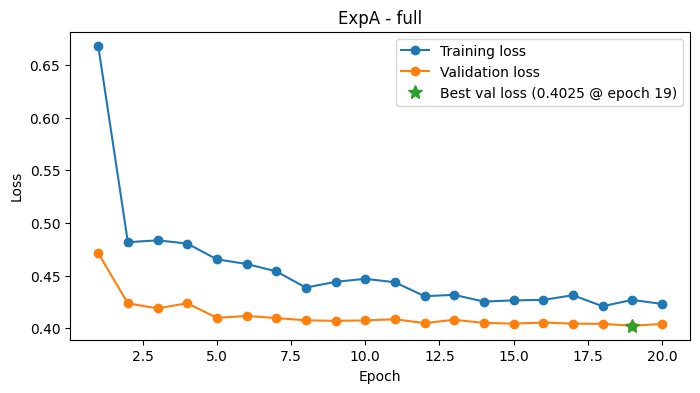

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Best Model Loaded
Training Time = 1025.270 sec
ExpA, full, Testing loss: 0.4030

 ---- evaluation metrics ----
 Sample 100/100     

Saved: /content/drive/MyDrive/Semester_2_2026/Generative AI/A3LoRa/results/ExpA_metrics_Testset.csv
Mean latency: 1.7200
Mean RTF: 0.2452
Mean WER: 6.86%
Each file in the testing was generated 5 times, and the mean result was calculated.

Saved: /content/drive/MyDrive/Semester_2_2026/Generative AI/A3LoRa/results/ExpA_metrics_generation.csv
ExpA Result
          file  best_wer  latency_seconds  audio_seconds      rtf  wer_percent
T5_ExpA_01.wav       0.0         0.785900       3.193600 0.246139     0.000000
T5_ExpA_02.wav       0.0         0.573555       2.310400 0.248243     6.666667
T5_ExpA_03.wav       0.0         0.503739       1.945600 0.258623     0.000000
T5_ExpA_04.wav       0.0         0.742608       3.033600 0.244784     0.000000
T5_ExpA_05.wav       0.0         0.718061       2.873600 0.249918     0.000000
T5_ExpA_06.wav       0.0         0.6698

Each prompts was generated 5 times, and the mean result was calculated.
----------------------------------------------------------------------


In [ ]:
run_experiment(experiments[1])

**23. Run experiment B: 1,000 samples, learning rate `1e-4`.**



 -----------Starting ExpB -----------


Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Mode: full
Trainable parameters: 144,431,684/144,431,684 (100.000%)
Epoch     Batch               Train Loss   Validation Loss
----------------------------------------------------------
1/20      100/100                 0.5584            0.4371


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

2/20      100/100                 0.4678            0.4173


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

9/20      100/100                 0.4320            0.4124
10/20     100/100                 0.4413            0.4284
11/20     100/100                 0.4329            0.4146
12/20     100/100                 0.4122            0.4140
13/20     100/100                 0.4228            0.4199
14/20     100/100                 0.4147            0.4083


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

15/20     100/100                 0.4093            0.4091
16/20     100/100                 0.4077            0.4149
17/20     100/100                 0.4331            0.4191
18/20     100/100                 0.4125            0.4183
19/20     100/100                 0.4196            0.4173
20/20     100/100                 0.4047            0.4121
Training completed
Best validation loss: 0.4083


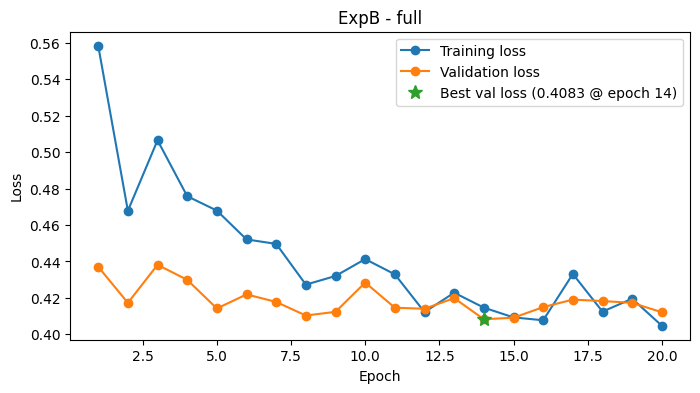

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Best Model Loaded
Training Time = 960.562 sec
ExpB, full, Testing loss: 0.4096

 ---- evaluation metrics ----
 Sample 100/100     

Saved: /content/drive/MyDrive/Semester_2_2026/Generative AI/A3LoRa/results/ExpB_metrics_Testset.csv
Mean latency: 1.6801
Mean RTF: 0.2480
Mean WER: 7.11%
Each file in the testing was generated 5 times, and the mean result was calculated.

Saved: /content/drive/MyDrive/Semester_2_2026/Generative AI/A3LoRa/results/ExpB_metrics_generation.csv
ExpB Result
          file  best_wer  latency_seconds  audio_seconds      rtf  wer_percent
T5_ExpB_01.wav       0.0         0.806541         3.1872 0.253321     2.222222
T5_ExpB_02.wav       0.0         0.596653         2.3808 0.250612     0.000000
T5_ExpB_03.wav       0.0         0.510924         1.9072 0.267837     0.000000
T5_ExpB_04.wav       0.0         0.854549         3.4688 0.246676     0.000000
T5_ExpB_05.wav       0.0         0.734668         2.8800 0.255134     0.000000
T5_ExpB_06.wav       0.0         0.72244

Each prompts was generated 5 times, and the mean result was calculated.
----------------------------------------------------------------------


In [ ]:
run_experiment(experiments[2])

**24. Run experiment C: 2,000 samples, learning rate `1e-5`.**



 -----------Starting ExpC -----------


Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Mode: full
Trainable parameters: 144,431,684/144,431,684 (100.000%)
Epoch     Batch               Train Loss   Validation Loss
----------------------------------------------------------
1/20      200/200                 0.5800            0.4313


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

2/20      200/200                 0.4736            0.4141


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (19 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

18/20     200/200                 0.4156            0.3915


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

19/20     200/200                 0.4143            0.3922
20/20     200/200                 0.4134            0.3924
Training completed
Best validation loss: 0.3915


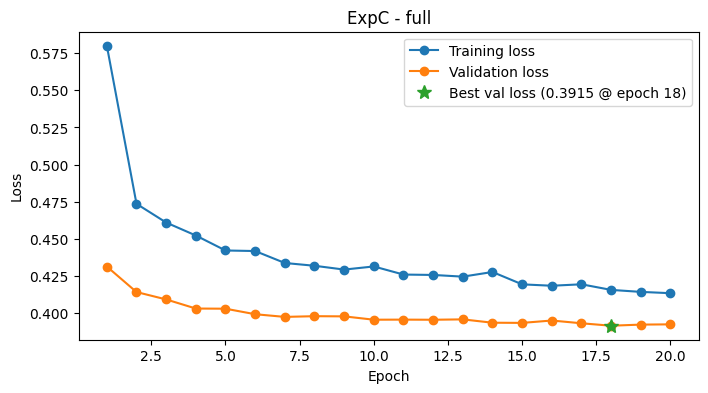

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Best Model Loaded
Training Time = 1694.397 sec
ExpC, full, Testing loss: 0.3959

 ---- evaluation metrics ----
 Sample 200/200     

Saved: /content/drive/MyDrive/Semester_2_2026/Generative AI/A3LoRa/results/ExpC_metrics_Testset.csv
Mean latency: 1.5967
Mean RTF: 0.2446
Mean WER: 4.36%
Each file in the testing was generated 5 times, and the mean result was calculated.

Saved: /content/drive/MyDrive/Semester_2_2026/Generative AI/A3LoRa/results/ExpC_metrics_generation.csv
ExpC Result
          file  best_wer  latency_seconds  audio_seconds      rtf  wer_percent
T5_ExpC_01.wav       0.0         0.767420       3.091200 0.248307          0.0
T5_ExpC_02.wav       0.0         0.558733       2.240000 0.249439          0.0
T5_ExpC_03.wav       0.0         0.502879       1.945600 0.258325          0.0
T5_ExpC_04.wav       0.0         0.767258       3.078400 0.249194          0.0
T5_ExpC_05.wav       0.0         0.708312       2.899200 0.244312          0.0
T5_ExpC_06.wav       0.0         0.7118

Each prompts was generated 5 times, and the mean result was calculated.
----------------------------------------------------------------------


In [ ]:
run_experiment(experiments[3])

**25. Run experiment D: 2,000 samples, learning rate `1e-4`.**



 -----------Starting ExpD -----------


Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Mode: full
Trainable parameters: 144,431,684/144,431,684 (100.000%)
Epoch     Batch               Train Loss   Validation Loss
----------------------------------------------------------
1/20      200/200                 0.5211            0.4301


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

2/20      200/200                 0.4698            0.4127


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

7/20      200/200                 0.4287            0.3996


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

8/20      200/200                 0.4234            0.4042
9/20      200/200                 0.4360            0.4186
10/20     200/200                 0.4389            0.4099
11/20     200/200                 0.4316            0.4104
12/20     200/200                 0.4246            0.4080
13/20     200/200                 0.4139            0.4017
14/20     200/200                 0.4200            0.4011
15/20     200/200                 0.4101            0.4037
16/20     200/200                 0.4140            0.4069
17/20     200/200                 0.4197            0.4048
18/20     200/200                 0.4093            0.4055
19/20     200/200                 0.4065            0.4060
20/20     200/200                 0.4026            0.4112
Training completed
Best validation loss: 0.3996


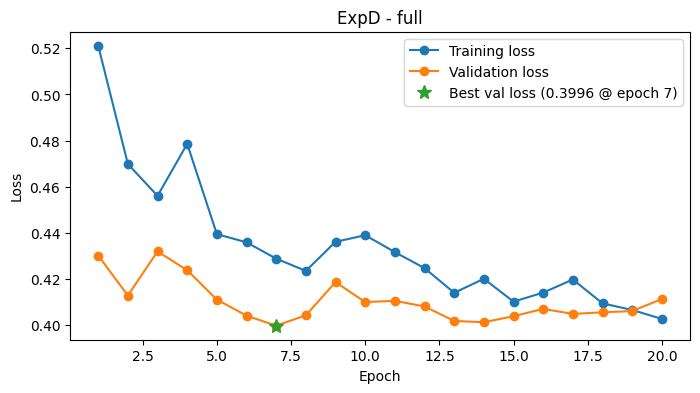

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Best Model Loaded
Training Time = 1702.708 sec
ExpD, full, Testing loss: 0.4048

 ---- evaluation metrics ----
 Sample 200/200     

Saved: /content/drive/MyDrive/Semester_2_2026/Generative AI/A3LoRa/results/ExpD_metrics_Testset.csv
Mean latency: 1.7570
Mean RTF: 0.2477
Mean WER: 8.61%
Each file in the testing was generated 5 times, and the mean result was calculated.

Saved: /content/drive/MyDrive/Semester_2_2026/Generative AI/A3LoRa/results/ExpD_metrics_generation.csv
ExpD Result
          file  best_wer  latency_seconds  audio_seconds      rtf  wer_percent
T5_ExpD_01.wav       0.0         0.787546         3.1360 0.251082     0.000000
T5_ExpD_02.wav       0.0         0.629640         2.2912 0.274694     0.000000
T5_ExpD_03.wav       0.0         0.568351         1.9840 0.286501     0.000000
T5_ExpD_04.wav       0.0         0.779201         3.1296 0.249224     0.000000
T5_ExpD_05.wav       0.0         0.744309         2.8416 0.262012     0.000000
T5_ExpD_06.wav       0.0         0.7071

Each prompts was generated 5 times, and the mean result was calculated.
----------------------------------------------------------------------


In [ ]:
run_experiment(experiments[4])

**26. Run experiment E: LoRA fine-tuning, 1,000 samples, learning rate `1e-5`.**


 -----------Starting ExpE -----------


Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Mode: lora
Trainable parameters: 2,292,992/146,724,676 (1.563%)
Epoch     Batch               Train Loss   Validation Loss
----------------------------------------------------------
1/20      100/100                 0.8090            0.7254


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved best LoRA adapter: /content/drive/MyDrive/Semester_2_2026/Generative AI/A3LoRa/checkpoints/ExpE
2/20      100/100                 0.8122            0.7197


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (33 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved best LoRA adapter: /content/drive/MyDrive/Semester_2_2026/Generative AI/A3LoRa/checkpoints/ExpE
20/20     100/100                 0.5162            0.4455


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved best LoRA adapter: /content/drive/MyDrive/Semester_2_2026/Generative AI/A3LoRa/checkpoints/ExpE
Training completed
Best validation loss: 0.4455


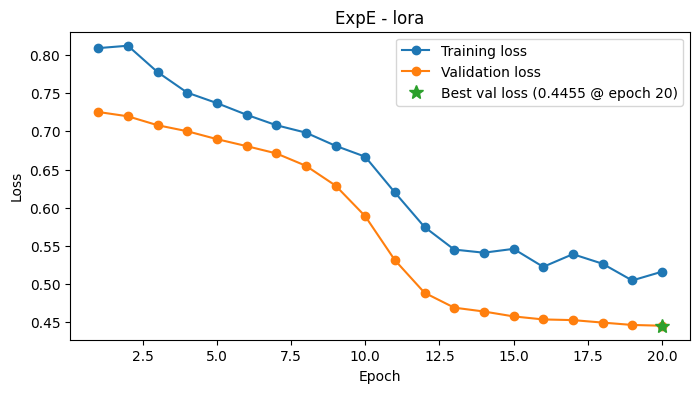

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/266 [00:00<?, ?it/s]

Loaded adapter: ['ljspeech']
Training Time = 1077.257 sec
ExpE, lora, Testing loss: 0.4427

 ---- evaluation metrics ----
 Sample 100/100     

Saved: /content/drive/MyDrive/Semester_2_2026/Generative AI/A3LoRa/results/ExpE_metrics_Testset.csv
Mean latency: 3.3960
Mean RTF: 0.5040
Mean WER: 5.24%
Each file in the testing was generated 5 times, and the mean result was calculated.

Saved: /content/drive/MyDrive/Semester_2_2026/Generative AI/A3LoRa/results/ExpE_metrics_generation.csv
ExpE Result
          file  best_wer  latency_seconds  audio_seconds      rtf  wer_percent
T5_ExpE_01.wav       0.0         1.551206       3.040000 0.510234          0.0
T5_ExpE_02.wav       0.0         1.157436       2.227200 0.519532          0.0
T5_ExpE_03.wav       0.0         1.299491       2.483200 0.524832          0.0
T5_ExpE_04.wav       0.0         1.448544       2.905600 0.498554          0.0
T5_ExpE_05.wav       0.0         1.423115       2.822400 0.504187          0.0
T5_ExpE_06.wav       0.0    

Each prompts was generated 5 times, and the mean result was calculated.
----------------------------------------------------------------------


In [ ]:
run_experiment(experiments[5])

**27. Run experiment F: LoRA fine-tuning, 1,000 samples, learning rate `1e-4`.**


 -----------Starting ExpF -----------


Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Mode: lora
Trainable parameters: 2,292,992/146,724,676 (1.563%)
Epoch     Batch               Train Loss   Validation Loss
----------------------------------------------------------
1/20      100/100                 0.7651            0.6594


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved best LoRA adapter: /content/drive/MyDrive/Semester_2_2026/Generative AI/A3LoRa/checkpoints/ExpF
2/20      100/100                 0.6160            0.4557


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (25 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved best LoRA adapter: /content/drive/MyDrive/Semester_2_2026/Generative AI/A3LoRa/checkpoints/ExpF
16/20     100/100                 0.4522            0.4130
17/20     100/100                 0.4571            0.4126
18/20     100/100                 0.4578            0.4119
19/20     100/100                 0.4472            0.4089


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved best LoRA adapter: /content/drive/MyDrive/Semester_2_2026/Generative AI/A3LoRa/checkpoints/ExpF
20/20     100/100                 0.4488            0.4097
Training completed
Best validation loss: 0.4089


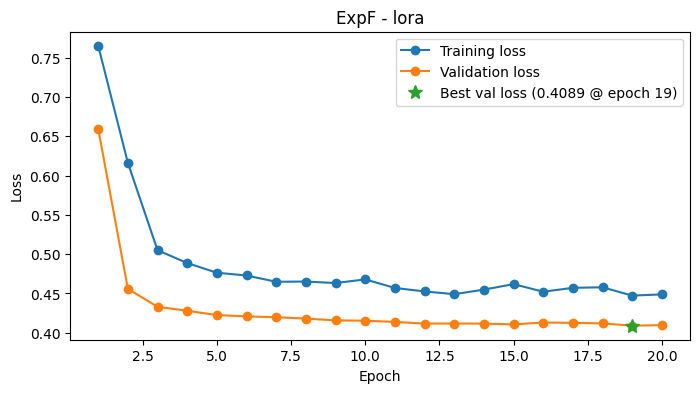

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/266 [00:00<?, ?it/s]

Loaded adapter: ['ljspeech']
Training Time = 1023.610 sec
ExpF, lora, Testing loss: 0.4151

 ---- evaluation metrics ----
 Sample 100/100     

Saved: /content/drive/MyDrive/Semester_2_2026/Generative AI/A3LoRa/results/ExpF_metrics_Testset.csv
Mean latency: 3.9233
Mean RTF: 0.5067
Mean WER: 13.80%
Each file in the testing was generated 5 times, and the mean result was calculated.

Saved: /content/drive/MyDrive/Semester_2_2026/Generative AI/A3LoRa/results/ExpF_metrics_generation.csv
ExpF Result
          file  best_wer  latency_seconds  audio_seconds      rtf  wer_percent
T5_ExpF_01.wav  0.000000         1.697727       3.289600 0.516563     0.000000
T5_ExpF_02.wav  0.000000         1.162017       2.233600 0.520355     0.000000
T5_ExpF_03.wav  0.000000         1.028408       1.939200 0.530082     0.000000
T5_ExpF_04.wav  0.000000         1.552282       3.033600 0.512087     0.000000
T5_ExpF_05.wav  0.000000         1.450018       2.790400 0.519747     0.000000
T5_ExpF_06.wav  0.000000   

Each prompts was generated 5 times, and the mean result was calculated.
----------------------------------------------------------------------


In [ ]:
run_experiment(experiments[6])

Saved the Speaker to the ckeck point, for Github

In [ ]:
for run in sorted(os.listdir(CHECKPOINT_DIR)):
    run_dir = CHECKPOINT_DIR / run
    if run_dir.is_dir():
        torch.save(speaker_embedding, run_dir / "speaker_embedding.pt")
        print("saved", run)

saved Exp0
saved ExpA
saved ExpB
saved ExpC
saved ExpD
saved ExpE
saved ExpF


In [ ]:
ZIP_DIR = PROJECT_ROOT / "release_zips"   # Folder to save zip files
ZIP_DIR.mkdir(parents=True, exist_ok=True)

run_names = ["ExpA", "ExpB", "ExpC", "ExpD", "ExpE", "ExpF"]   # Exp0 has no checkpoint

for run_name in run_names:
    run_checkpoint_dir = CHECKPOINT_DIR / run_name
    zip_path = ZIP_DIR / f"T5_{run_name}.zip"

    print(run_name, "speaker_embedding.pt found:", (run_checkpoint_dir / "speaker_embedding.pt").is_file())  # should be True

    !cd "{CHECKPOINT_DIR}" && zip -rq0 "/content/T5_{run_name}.zip" "{run_name}"   # zip in Colab first (faster)
    !cp "/content/T5_{run_name}.zip" "{zip_path}"                                   # copy zip to Drive

    print(f"Saved {zip_path.name}: {zip_path.stat().st_size / 1e6:.0f} MB")

ExpA speaker_embedding.pt found: True
Saved T5_ExpA.zip: 578 MB
ExpB speaker_embedding.pt found: True
Saved T5_ExpB.zip: 578 MB
ExpC speaker_embedding.pt found: True
Saved T5_ExpC.zip: 578 MB
ExpD speaker_embedding.pt found: True
Saved T5_ExpD.zip: 578 MB
ExpE speaker_embedding.pt found: True
Saved T5_ExpE.zip: 9 MB
ExpF speaker_embedding.pt found: True
Saved T5_ExpF.zip: 9 MB


In [ ]:
from google.colab import runtime
runtime.unassign()

## 1.4.1 Objective metric (minimum: 1) — report for each experiment

- **Latency:** The mean time to generate one test sentence, including SpeechT5 synthesis and vocoder processing. Each test sentence is generated five times, and the reported latency is averaged across all sentences and runs.
 100 sentences for expA/expB/expE/expF  and 200 for expC/expD.
- **Real-Time Factor (RTF):** Generation time divided by generated audio duration. Lower is faster.
- **Word Error Rate (WER):** Whisper `base.en` transcribes the generated audio; its text is compared with the reference sentence. lower value is better.

| Experiment | Method | Dataset subset | LR | Trainable parameters | Total parameters | Test sentences | Mean latency (s) ↓ | Mean RTF ↓ | Mean WER (%) ↓ |
|---|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Exp0 | Frozen baseline | 1,000 | N/A | 0 (0%) | 144,431,684 | 100 | 1.6037 | 0.2461 | 9.27 |
| ExpA | Full fine-tuning | 1,000 | 1e-5 | 144,431,684 (100%) | 144,431,684 | 100 | 1.7200 | 0.2452 | 6.86 |
| ExpB | Full fine-tuning | 1,000 | 1e-4 | 144,431,684 (100%) | 144,431,684 | 100 | 1.6881 | 0.2480 | 7.11 |
| **🥇 ExpC — 1st** | **Full fine-tuning** | **2,000** | **1e-5** | **144,431,684 (100%)** | **144,431,684** | **200** | **1.5967** | **0.2446** | **4.36** |
| ExpD | Full fine-tuning | 2,000 | 1e-4 | 144,431,684 (100%) | 144,431,684 | 200 | 1.7570 | 0.2477 | 8.61 |
| **🥈 ExpE — 2nd** | **LoRA** | **1,000** | **1e-5** | **2,292,992 (1.563%)** | **146,724,676** | **100** | **3.3960** | **0.5040** | **5.24** |
| ExpF | LoRA | 1,000 | 1e-4 | 2,292,992 (1.563%) | 146,724,676 | 100 | 3.9233 | 0.5067 | 13.80 |

LoRA inference showed higher latency despite using fewer trainable parameters. This is due the additional computation for mergeing the adaptor and model outputs.


## 1.4.2 Qualitative evaluation (required)

- **Prompts:** The same 12 prompts are used for every experiment:
    1. "The quick brown fox jumps over the lazy dog.",
    2. "Adelaide has great weather in spring.",
    3. "Thank you for listening to this file.",
    4. "Our group did excellent work on assignment 3.",
    5. "Can you hear the difference between these 2 voices?",
    6. "What a great result for our first experiment!",
    7. "We need clean text, and enough training time.",
    8. "The first model was fast, the second model sounded more natural.",
    9. "I don't believe it is ready, but we will try it again tomorrow.",
    10. "At the university, Dr. Brown and Mrs. Lee met Mr. Clark.",
    11. "The class begins at nine and there are forty-five students in the class.",
    12. "The model should be able to read new sentences clearly, and maintain a consistent reading speed; and pause at the correct location."

    
- **Generated WAV files:** Saved in `wav_examples/`, with names such as `expA_01.wav` through `expD_12.wav`. After all four runs, we got 60 files.

| Experiment | Method | LR | Generated sentences | Mean latency (s) ↓ | Mean RTF ↓ | Mean WER (%) ↓ |
|---|---|---:|---:|---:|---:|---:|
| Exp0 | Frozen baseline | N/A | 12 | 0.8998 | 0.2538 | 1.97 |
| ExpA | Full fine-tuning | 1e-5 | 12 | 0.9631 | 0.2492 | 0.56 |
| ExpB | Full fine-tuning | 1e-4 | 12 | 1.0745 | 0.2515 | 3.58 |
| **ExpC — joint lowest WER** | **Full fine-tuning** | **1e-5** | **12** | **0.9437** | **0.2485** | **0.00** |
| ExpD | Full fine-tuning | 1e-4 | 12 | 1.0864 | 0.2556 | 1.52 |
| **ExpE — joint lowest WER** | **LoRA** | **1e-5** | **12** | **1.8794** | **0.5085** | **0.00** |
| ExpF | LoRA | 1e-4 | 12 | 2.2080 | 0.5125 | 2.88 |

*Each sentence was generated five times. Generated-output results are separate from the held-out test-set results.*






## 1.4.3 Coding practice & clarity

- **Code organization:** Data preparation, training, evaluation, and audio generation are separate functions in the code notebook.
- **Reproducibility:** Seed 42 is used for sampling, splitting, and training. Each experiment starts from same pretrained model. The best checkpoint is saved in the Drive, and all runs use the same  12 qualitative prompts.

## 1.4.4 Attribution / external resources

- **Dataset:** [LJSpeech](https://keithito.com/LJ-Speech-Dataset/).
- **Libraries/toolkits:** PyTorch, Transformers, SpeechBrain, librosa, SoundFile, pandas, and JiWER.
- **Pretrained checkpoints:** [SpeechT5 TTS](https://huggingface.co/microsoft/speecht5_tts), [SpeechT5 HiFi-GAN](https://huggingface.co/microsoft/speecht5_hifigan), [SpeechBrain x-vector speaker model](https://huggingface.co/speechbrain/spkrec-xvect-voxceleb), and [OpenAI Whisper](https://github.com/openai/whisper) `base.en`.
- **Tutorials or code snippets adapted:** [Hugging Face Text-to-speech guide](https://huggingface.co/docs/transformers/tasks/text-to-speech). OpenAI Codex assisted with the code.

# Final verification (before submission)

## Restart & run

- [x] Restart the kernel and run all cells you want the marker to execute.
- [x] No hidden dependencies on local machine paths.
- [x] Commands and paths work from the submission root.

## Confirm required artefacts exist

- [x] `wav_examples/` contains generated `.wav` outputs for 12 prompts.
- [x] Objective metric results for each experiment are clearly reported in the notebook.
- [x] A dependency file (`requirements.txt`) is included.
- [x] The inference entrypoint takes text and outputs a WAV file.

## Marker instructions

1. Install the packages from `requirements.txt` and set the project and LJSpeech dataset paths.
2. Run the notebook setup cells to prepare the data, processor, vocoder, and speaker embedding.
3. Run `run_experiment(experiments[0])` for the pretrained Model,
4. Run `run_experiment(experiments[1])` through `run_experiment(experiments[6])`. Each call trains its model, loads its best checkpoint, evaluates it, and generates WAV samples.

